# Unconditioned Flow Matching on MNIST

In [19]:
import time

import torch 
from torch import nn, Tensor
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import make_grid
import numpy as np

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')

### Load MNIST dataset

In [4]:


# Normalize pixel values from [0, 1] to [-1, 1] so the data matches a standard
# Gaussian source for flow matching.
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_dataset = datasets.MNIST(root='../data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='../data', train=False, download=True, transform=transform)

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'Train samples: {len(train_dataset)}, Test samples: {len(test_dataset)}')
images, labels = next(iter(train_loader))
print(f'Batch images shape: {images.shape}, labels shape: {labels.shape}')

Train samples: 60000, Test samples: 10000
Batch images shape: torch.Size([128, 1, 28, 28]), labels shape: torch.Size([128])


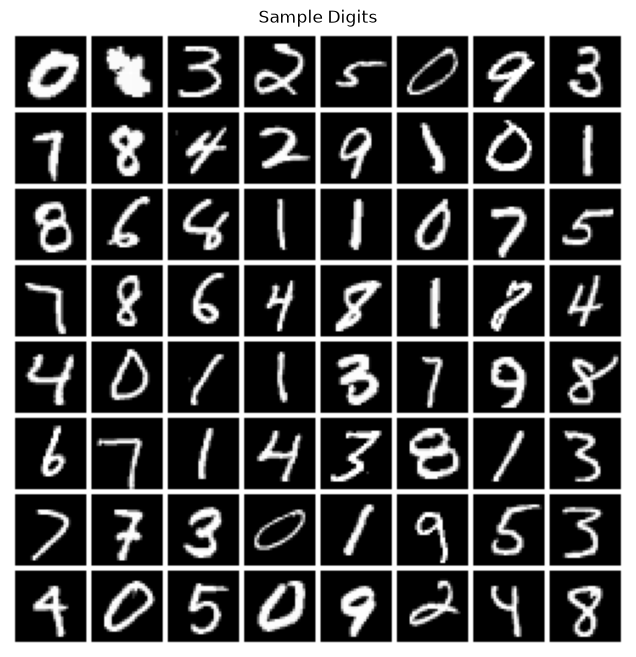

In [5]:
## Display some sample digits

def show_samples(images: Tensor, nrow: int=8, ax=None):
    # images = (images + 1) / 2  # denormalize
    images = images.clamp(0, 1)
    grid = make_grid(images[:nrow**2], nrow, padding=2, pad_value=1)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 8))
    ax.set_aspect('equal')
    ax.set_title('Sample Digits')
    ax.imshow(grid.permute(1, 2, 0).cpu())
    ax.axis('off')
    return ax

show_samples(images);

### Train unconditioned FM

In [9]:
class Flow(nn.Module):

    def __init__(self, dim: int=28*28, h: int=128):
        super().__init__()
        self.dim = dim
        self.h = h

        self.net = nn.Sequential(
            nn.Linear(dim+1, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, h),
            nn.ReLU(),
            nn.Linear(h, 2*h),
            nn.ReLU(),
            nn.Linear(2*h, dim),
        )
    def forward(self, x, t):
        x_t = torch.cat([x, t], dim=1)
        return self.net(x_t)

    def step(self, x_t: Tensor, t_start: float, t_end: float):
        t_start = t_start.view(1, 1).expand(x_t.shape[0], 1)
        dt = t_end - t_start
        return x_t + dt * self(x_t + self(x_t, t=t_start)*dt/2, t=(t_start + t_end)/2)



In [8]:
N_EPOCHS = 50

flow = Flow(h=256).to(device)
opt = torch.optim.Adam(flow.parameters(), lr=1e-3)

for e in range(N_EPOCHS):
    for i, (x, _) in enumerate(train_loader):
        x_1 = x.view(-1, 784).to(device)

        t = torch.rand(x.shape[0], 1, device=x_1.device)
        x_0 = torch.randn_like(x_1)*0.2 + 0.5
        dx_t = x_1 - x_0
        x_t = (1-t)*x_0 + t * x_1
        flow_pred = flow(x_t, t)

        loss = (flow_pred - dx_t).pow(2).sum(dim=1).mean()
        loss.backward()
        opt.step()
        opt.zero_grad()

        if i % 50 == 0:
            print(f'Epoch: {e}, Iter: {i}, Loss: {loss.item():.4f}')


Epoch: 0, Iter: 0, Loss: 214.4180
Epoch: 0, Iter: 50, Loss: 85.0983
Epoch: 0, Iter: 100, Loss: 77.4759
Epoch: 0, Iter: 150, Loss: 70.2414
Epoch: 0, Iter: 200, Loss: 64.7878
Epoch: 0, Iter: 250, Loss: 66.4900
Epoch: 0, Iter: 300, Loss: 61.3462
Epoch: 0, Iter: 350, Loss: 60.5459
Epoch: 0, Iter: 400, Loss: 60.6357
Epoch: 0, Iter: 450, Loss: 58.7300
Epoch: 1, Iter: 0, Loss: 57.0106
Epoch: 1, Iter: 50, Loss: 57.6221
Epoch: 1, Iter: 100, Loss: 56.0544
Epoch: 1, Iter: 150, Loss: 61.1894
Epoch: 1, Iter: 200, Loss: 56.0283
Epoch: 1, Iter: 250, Loss: 56.0707
Epoch: 1, Iter: 300, Loss: 56.2016
Epoch: 1, Iter: 350, Loss: 55.6679
Epoch: 1, Iter: 400, Loss: 57.3116
Epoch: 1, Iter: 450, Loss: 56.6449
Epoch: 2, Iter: 0, Loss: 55.7460
Epoch: 2, Iter: 50, Loss: 54.2183
Epoch: 2, Iter: 100, Loss: 55.5858
Epoch: 2, Iter: 150, Loss: 56.1752
Epoch: 2, Iter: 200, Loss: 56.7113
Epoch: 2, Iter: 250, Loss: 55.0766
Epoch: 2, Iter: 300, Loss: 52.6586
Epoch: 2, Iter: 350, Loss: 53.7033
Epoch: 2, Iter: 400, Loss: 5

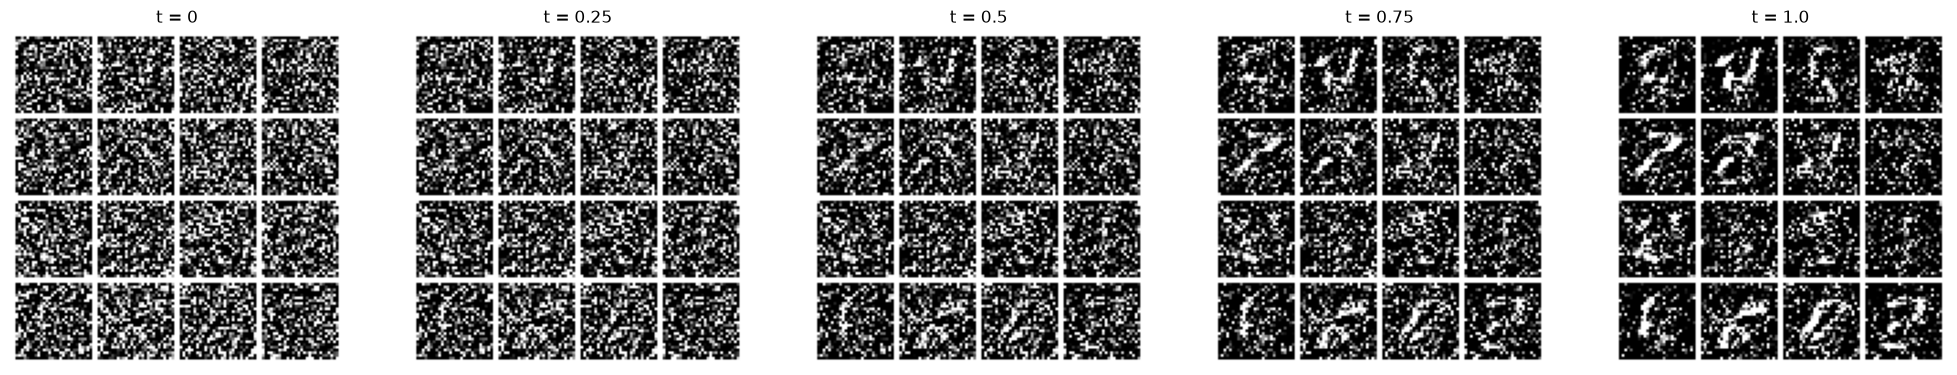

In [9]:
x = torch.randn(16, 784).to(device)
n_steps = 100
time_steps = torch.linspace(0, 1.0, n_steps + 1)

# Precompute the point cloud at every time step.
states = [x]
with torch.no_grad():
    for i in range(n_steps):
        x = flow.step(x_t=x, t_start=time_steps[i].to(device), t_end=time_steps[i + 1].to(device))
        states.append(x)
states = [s.detach() for s in states]

fig, ax = plt.subplots(1, 5, figsize=(25, 10))
ax = ax.reshape(-1)
ax[0] = show_samples(states[0].view(-1, 1, 28, 28), nrow=4, ax=ax[0])
ax[0].set_title('t = 0')
ax[1] = show_samples(states[25].view(-1, 1, 28, 28), nrow=4, ax=ax[1])
ax[1].set_title('t = 0.25')
ax[2] = show_samples(states[50].view(-1, 1, 28, 28), nrow=4, ax=ax[2])
ax[2].set_title('t = 0.5')
ax[3] = show_samples(states[75].view(-1, 1, 28, 28), nrow=4, ax=ax[3])
ax[3].set_title('t = 0.75')
ax[4] = show_samples(states[-1].view(-1, 1, 28, 28), nrow=4, ax=ax[4])
ax[4].set_title('t = 1.0')

plt.show()
